# Exploration des données : Bacterial Gene Expression

Ce notebook décrit les données du challenge avant d'écrire un modèle :

1. ce qu'est une observation et ce que le modèle doit prédire,
2. le sens de chaque colonne de la table des gènes et de la table des runs,
3. **les valeurs manquantes** (combien, où, et pourquoi),
4. la cible `readcount` et la loi binomiale négative (`mu`, `sigma`),
5. les régions A, B, C, D,
6. ce que contient un fichier génome `.gbff`.

**Lancer** : noyau `pytorch_py312`, après `benchopt prepare` (ou `python tools/prepare_lowmem.py --mode train`).
Le notebook lit `benchmark/data/bacteria/train/` et retombe sur `debug/` si `train/` n'existe pas.

## 0. Chargement

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import nbinom, poisson

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Project root = first parent folder that holds benchmark/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "benchmark").is_dir())
sys.path.insert(0, str(ROOT / "benchmark"))
from benchmark_utils.nb_loss import nb_nll, NLL_CAP

DATA = ROOT / "benchmark" / "data" / "bacteria"
MODE = "train" if (DATA / "train" / "train.parquet").exists() else "debug"
PREP = DATA / MODE
GENOMES = DATA / "genomes"
print("root   :", ROOT)
print("mode   :", MODE, "->", PREP)
print("genomes:", len(list(GENOMES.glob("*.gbff"))), "fichiers .gbff")

root   : D:\Loisir\Code_python\codabench_virtual_bacteria
mode   : train -> D:\Loisir\Code_python\codabench_virtual_bacteria\benchmark\data\bacteria\train
genomes: 258 fichiers .gbff


In [2]:
genes = pd.read_csv(PREP / "feature_annotation.csv", low_memory=False)
runs = pd.read_csv(PREP / "condition_annotation.csv", low_memory=False)

# Observations: only the keys and the target, the offsets live in the two tables above
OBS_COLS = ["species", "genome_id", "feature_id", "run_accession", "readcount"]
splits = {name: pd.read_parquet(PREP / f"{name}.parquet", columns=OBS_COLS)
          for name in ["train", "A", "B", "C", "D"]}
for name, df in splits.items():
    print(f"{name:>5} : {len(df):>11,} observations, {df.memory_usage(deep=True).sum() / 1e9:.2f} Go en mémoire")
print(f"genes : {genes.shape}")
print(f"runs  : {runs.shape}")

train :  69,202,809 observations, 1.23 Go en mémoire
    A :   3,260,298 observations, 0.11 Go en mémoire
    B :     803,581 observations, 0.07 Go en mémoire


    C :     311,029 observations, 0.06 Go en mémoire
    D :       3,741 observations, 0.06 Go en mémoire
genes : (853339, 13)
runs  : (19513, 20)


## 1. Une observation = un gène dans un run

Chaque ligne des fichiers `train`, `A`, `B`, `C`, `D` est un couple **(gène, run)** :

- le gène est identifié par la paire **`(genome_id, feature_id)`** (un `feature_id` seul ne suffit pas, voir plus bas),
- le run est identifié par **`run_accession`** (unique dans tout le jeu, chaque run appartient à un seul génome),
- la cible est **`readcount`**, le nombre de lectures RNA-seq tombées sur ce gène dans ce run.

Le modèle ne sort donc **pas un vecteur pour tous les gènes d'un génome**. On lui donne une ligne (quel gène, quel run,
et tout ce qu'on sait sur eux) et il rend deux nombres pour cette ligne : `mu` et `sigma`. C'est ce qui permet de gérer des
génomes qui n'ont pas le même nombre de gènes.

In [3]:
splits["train"].head()

,species,genome_id,feature_id,run_accession,readcount
0,Acetivibrio_thermocellus,GCF_000015865.1,cds-WP_235715177.1,SRR1017581,74.0
1,Acetivibrio_thermocellus,GCF_000015865.1,cds-WP_003511903.1,SRR1017581,35.0
2,Acetivibrio_thermocellus,GCF_000015865.1,cds-WP_003511911.1,SRR1017581,7212.0
3,Acetivibrio_thermocellus,GCF_000015865.1,cds-WP_003518951.1,SRR1017581,7.0
4,Acetivibrio_thermocellus,GCF_000015865.1,cds-WP_235715176.1,SRR1017581,27.0


In [4]:
def summary(df):
    return pd.Series({
        "observations": len(df),
        "gènes (genome_id, feature_id)": df.groupby(["genome_id", "feature_id"], observed=True).ngroups,
        "runs": df["run_accession"].nunique(),
        "génomes": df["genome_id"].nunique(),
        "espèces": df["species"].nunique(),
    })

pd.DataFrame({name: summary(df) for name, df in splits.items()}).T.style.format("{:,}")

,observations,"gènes (genome_id, feature_id)",runs,génomes,espèces
train,"69,202,809","786,039","19,170",243,87
A,"3,260,298","152,183","2,636",131,78
B,"803,581","151,484",278,38,38
C,"311,029","3,496","19,170",243,87
D,"3,741",643,278,38,38


In [5]:
print("feature_id unique à lui seul         :", genes["feature_id"].is_unique)
print("(genome_id, feature_id) unique       :", not genes.duplicated(["genome_id", "feature_id"]).any())
print("run_accession unique dans les runs   :", runs["run_accession"].is_unique)
shared = genes["feature_id"].value_counts()
print(f"feature_id partagés par plusieurs génomes : {(shared > 1).sum():,} (ex. {shared.index[0]} dans {shared.iloc[0]} génomes)")

feature_id unique à lui seul         : False
(genome_id, feature_id) unique       : True
run_accession unique dans les runs   : True


feature_id partagés par plusieurs génomes : 109,681 (ex. cds-WP_000487600.1 dans 39 génomes)


## 2. La table des gènes (`feature_annotation.csv`)

Une ligne par gène. Ce sont les colonnes `gene_metadata_features` passées au solver.

| Colonne | Ce que c'est |
|---|---|
| `species` | Nom de l'espèce. Attention, **`Picard` n'est pas une espèce** : ce sont des souches naturelles d'*E. coli* (collection ECOR, NILS), assemblées en contigs et rattachées à *E. coli* K-12 (voir 2.3). `Sulfolobus_acidocaldarius` est une archée, pas une bactérie. |
| `genome_id` | Identifiant NCBI de l'assemblage du génome (`GCF_...` = RefSeq). Une espèce peut avoir plusieurs génomes (plusieurs souches). |
| `feature_id` | Identifiant du gène dans son génome, en général `cds-<id protéine>`. Les ids `WP_...` sont des protéines RefSeq partagées entre souches, d'où l'identifiant composé `(genome_id, feature_id)`. |
| `ref_genome_id` | Le **génome de référence de l'espèce** (une souche modèle, par exemple *E. coli* K-12 MG1655 = `GCF_000005845.2`). Un seul par espèce. |
| `ref_feature_id` | Le **gène équivalent (orthologue) dans ce génome de référence**. C'est le lien qui dit « ce gène de la souche X est le même gène que tel gène de la souche de référence ». |
| `homology` | Le **score de similarité** entre le gène et son orthologue de référence (de 0,62 à 1, médiane 0,994). 1 veut dire séquence identique. |
| `Chr` | La **séquence (chromosome, plasmide ou contig)** du `.gbff` qui porte le gène. `NC_` et `NZ_CP` sont des chromosomes ou plasmides complets, `contig_<i>` un morceau d'un génome assemblé en brouillon. |
| `Start`, `End` | Position du gène sur cette séquence, en paires de bases, **en base 1, bornes incluses**. Texte car quelques gènes (0,07 %) sont en plusieurs morceaux `a;b`. |
| `Strand` | Le **brin** qui porte le gène : `+` (lu de gauche à droite) ou `-` (lu de droite à gauche, sur le brin complémentaire). |
| `Length` | La **longueur du gène** en paires de bases, exactement `End - Start + 1`. C'est une caractéristique du gène, pas un hyperparamètre. |
| `log_length_ratio` | `log(Length)` moins une constante propre au génome. C'est un **offset** : un gène deux fois plus long capte deux fois plus de lectures à expression égale. |
| `on_contig_edge` | `True` si le gène touche le bout d'un contig, donc **probablement coupé** par l'assemblage (294 gènes seulement). |

### 2.1 Coordonnées : `Chr`, `Start`, `End`, `Strand`, `Length`

In [6]:
prefix = genes["Chr"].astype(str).str.extract(r"^([A-Za-z_]+)")[0]
print("Préfixes de Chr :", prefix.value_counts().to_dict())
print("Séquences par génome :", genes.groupby("genome_id")["Chr"].nunique().describe().round(1).to_dict())

single = ~genes["Start"].astype(str).str.contains(";")
g1 = genes[single]
print("Length == End - Start + 1 :", (g1["Length"] == g1["End"].astype(int) - g1["Start"].astype(int) + 1).mean())
print("Gènes en plusieurs morceaux :", (~single).sum())
genes.loc[~single, ["species", "feature_id", "Chr", "Start", "End", "Strand", "Length"]].head(3)

Préfixes de Chr : {'NC_': 390452, 'NZ_CP': 246843, 'contig_': 57540, 'NZ_CM': 9638, 'NZ_KI': 9136, 'CP': 7513, 'NZ_HG': 6847, 'NZ_OV': 5973, 'NZ_LS': 5862, 'NZ_LR': 5440, 'NZ_JDWN': 4610, 'NZ_CDZJCY': 4495, 'NZ_CABFNM': 4171, 'NZ_JRYM': 4097, 'NZ_AQEC': 3923, 'NZ_MJIN': 3920, 'NZ_AQGG': 3892, 'NZ_MJIO': 3886, 'NZ_JHRA': 3830, 'NZ_JHRM': 3804, 'BA': 3725, 'NZ_JHRC': 3600, 'NZ_JHQZ': 3534, 'NZ_AHGQ': 3529, 'NZ_LT': 3490, 'NZ_AYPR': 3456, 'NZ_AKGH': 3444, 'NZ_JEZL': 3427, 'NZ_JHUI': 3117, 'NZ_MOLZ': 3081, 'NZ_AYTU': 2823, 'NZ_AGRI': 2704, 'NZ_ABSA': 2534, 'NZ_KB': 2501, 'NZ_AZCQ': 2297, 'NZ_AWQJ': 1837, 'NZ_GG': 1814, 'NZ_DS': 1808, 'NZ_AQWT': 1769, 'NZ_AKVY': 1755, 'NZ_AHRC': 1735, 'NZ_AILS': 1723, 'NZ_AIKI': 1719, 'NZ_AGPO': 1710, 'NZ_AFGA': 1676, 'NZ_AJZS': 1670, 'NZ_OU': 677, 'NZ_KV': 307, 'AB': 5}
Séquences par génome : {'count': 243.0, 'mean': 11.3, 'std': 33.3, 'min': 1.0, '25%': 2.0, '50%': 2.0, '75%': 4.0, 'max': 382.0}


Length == End - Start + 1 : 1.0
Gènes en plusieurs morceaux : 563


,species,feature_id,Chr,Start,End,Strand,Length
1750,Acetivibrio_thermocellus,cds-WP_014522625.1,NC_017304.1;NC_017304.1,2170340;2171394,2171392;2171468,-;-,1128.0
3155,Acetivibrio_thermocellus,cds-WP_200859110.1,NC_009012.1;NC_009012.1,457499;457575,457573;458627,+;+,1128.0
3354,Acetivibrio_thermocellus,cds-WP_011838186.1,NC_009012.1;NC_009012.1,720606;721492,721490;721758,-;-,1152.0


écart-type de c dans un génome (max) : 8.91854719679682e-16


exp(c) typique : {'count': 243.0, 'mean': 767.0, 'std': 48.0, 'min': 621.0, '25%': 750.0, '50%': 767.0, '75%': 799.0, 'max': 941.0}
corr(c, moyenne de log(Length) du génome) : 1.0


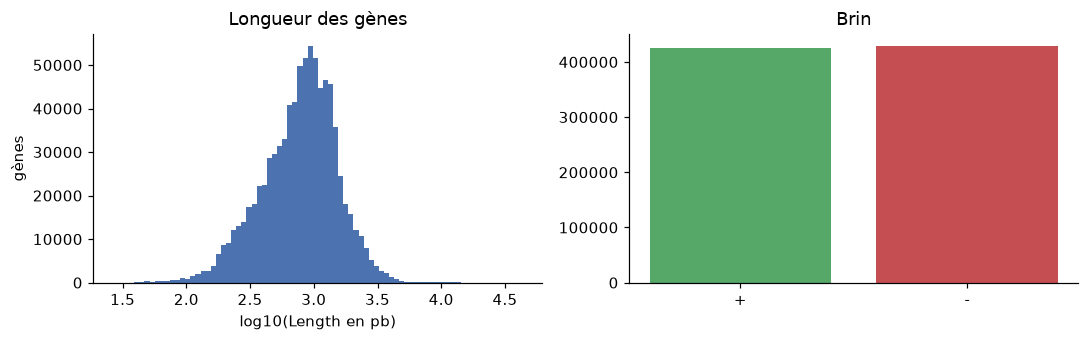

In [7]:
# log_length_ratio = log(Length) - c(genome): check that c is constant inside each genome
c = np.log(genes["Length"]) - genes["log_length_ratio"]
per_genome = c.groupby(genes["genome_id"]).agg(["mean", "std"])
geo_mean = np.log(genes["Length"]).groupby(genes["genome_id"]).mean()
print("écart-type de c dans un génome (max) :", per_genome["std"].max())
print("exp(c) typique :", np.exp(per_genome["mean"]).describe().round(0).to_dict())
print("corr(c, moyenne de log(Length) du génome) :", np.corrcoef(per_genome["mean"], geo_mean.loc[per_genome.index])[0, 1].round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(np.log10(genes["Length"]), bins=80, color="#4C72B0")
ax[0].set(xlabel="log10(Length en pb)", ylabel="gènes", title="Longueur des gènes")
ax[1].bar(["+", "-"], genes["Strand"].str[0].value_counts().reindex(["+", "-"]), color=["#55A868", "#C44E52"])
ax[1].set(title="Brin")
plt.tight_layout()

### 2.2 `on_contig_edge`

In [8]:
edge = genes[genes["on_contig_edge"]]
print(f"{len(edge)} gènes au bord d'un contig, dans {edge['genome_id'].nunique()} génomes")
print(edge["species"].value_counts().head(5).to_dict())
edge[["species", "genome_id", "feature_id", "Chr", "Start", "End", "Length"]].head(4)

294 gènes au bord d'un contig, dans 85 génomes
{'Escherichia_coli': 87, 'Microcystis_aeruginosa': 25, 'Lactiplantibacillus_plantarum': 22, 'Streptococcus_mutans': 21, 'Neisseria_gonorrhoeae': 17}


,species,genome_id,feature_id,Chr,Start,End,Length
6333,Acinetobacter_baumannii,GCF_000581515.1,cds-WP_003313048.1,NZ_JEZL01000004.1,1,384,384.0
6512,Acinetobacter_baumannii,GCF_000581515.1,cds-WP_031944326.1,NZ_JEZL01000005.1,1,273,273.0
7160,Acinetobacter_baumannii,GCF_000581515.1,cds-WP_000324576.1,NZ_JEZL01000010.1,1,340,340.0
8146,Acinetobacter_baumannii,GCF_000581515.1,cds-WP_031992272.1,NZ_JEZL01000024.1,1,813,813.0


### 2.3 `ref_genome_id`, `ref_feature_id`, `homology`

Pour chaque espèce qui a plusieurs souches, les organisateurs ont choisi **une souche de référence**, puis relié chaque
gène des autres souches à son équivalent dans cette référence. C'est le moyen de dire qu'un gène d'une souche nouvelle
est « le même » qu'un gène déjà bien mesuré ailleurs. C'est donc une piste majeure pour la région C (gène nouveau).

In [9]:
sp_of_genome = genes.drop_duplicates("genome_id").set_index("genome_id")["species"]
linked = genes.dropna(subset=["ref_feature_id"])
print("génomes de référence par espèce :", linked.groupby("species")["ref_genome_id"].nunique().value_counts().to_dict())
print("génome de référence présent dans le jeu :", linked["ref_genome_id"].isin(sp_of_genome.index).mean().round(3))
print("référence de la même espèce :", (linked["ref_genome_id"].map(sp_of_genome) == linked["species"]).mean().round(3))
print("feature_id == ref_feature_id (même protéine RefSeq) :", (linked["feature_id"] == linked["ref_feature_id"]).mean().round(3))
print("\nRéférence de 'Picard' :", linked.loc[linked["species"] == "Picard", "ref_genome_id"].map(sp_of_genome).value_counts().to_dict())
linked[["species", "genome_id", "feature_id", "ref_genome_id", "ref_feature_id", "homology"]].sample(5, random_state=0)

génomes de référence par espèce : {1: 44}
génome de référence présent dans le jeu : 0.953


référence de la même espèce : 0.846
feature_id == ref_feature_id (même protéine RefSeq) : 0.248

Référence de 'Picard' : {'Escherichia_coli': 57540}


,species,genome_id,feature_id,ref_genome_id,ref_feature_id,homology
830803,Vibrio_vulnificus,GCF_002224265.1,cds-WP_017422600.1,GCF_000186585.1,cds-WP_015727821.1,0.948
625858,Rhodobacter_capsulatus,GCF_000505785.1,cds-WP_013066607.1,GCF_000021865.1,cds-WP_013066607.1,1.000
336701,Klebsiella_pneumoniae,GCF_000699345.1,cds-WP_002898425.1,GCF_000465975.2,cds-WP_002898425.1,0.995
445479,Mycolicibacterium_smegmatis,GCF_000331165.2,cds-WP_003894377.1,GCF_000767605.1,cds-WP_011728745.1,0.962
219460,Escherichia_coli,GCF_016864475.1,cds-WP_000854560.1,GCF_000005845.2,cds-NP_416092.1,0.989


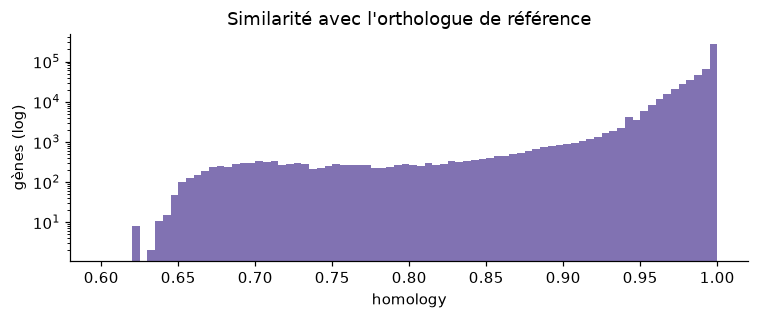

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(linked["homology"], bins=np.linspace(0.6, 1.0, 81), color="#8172B2")
ax.set_yscale("log")
ax.set(xlabel="homology", ylabel="gènes (log)", title="Similarité avec l'orthologue de référence")
plt.tight_layout()

## 3. La table des runs (`condition_annotation.csv`)

Une ligne par run RNA-seq. Ce sont les colonnes `condition_metadata_features` passées au solver.

| Colonne | Ce que c'est |
|---|---|
| `species`, `genome_id` | Le génome sur lequel les lectures du run ont été alignées. |
| `prj_accession` | Le projet NCBI (BioProject) : un même labo, une même étude. Les runs d'un projet se ressemblent. |
| `run_accession` | L'identifiant du run (SRR, ERR, DRR). Clé de jointure avec les observations. |
| `experiment_accession` | L'expérience NCBI (SRX...). Plusieurs runs peuvent être des réplicats d'une même expérience. |
| `log_size_factor` | **Offset de profondeur de séquençage** : un run séquencé deux fois plus profond donne deux fois plus de lectures partout. |
| `condition_confidence` | Confiance de la curation des conditions (`high`, `medium`, `low`). |
| `is_wild_type` | Souche sauvage (`True`) ou mutant (`False`). |
| `medium_category`, `medium_name` | Le milieu de culture (catégorie, puis nom libre, ex. `LB`, `M9`). |
| `temperature_celsius`, `ph` | Température et pH de culture. |
| `oxygen_condition`, `agitation_rpm` | Aérobie, anaérobie ou microaérobie, et vitesse d'agitation. |
| `growth_mode`, `growth_phase`, `od600` | Mode de culture (batch, chemostat, biofilm), phase de croissance, densité optique. |
| `has_perturbation`, `perturbation_category`, `perturbation_compound` | Stress ou traitement appliqué (antibiotique, carence, choc acide...). |

In [11]:
known = runs.dropna(subset=["medium_category", "temperature_celsius", "growth_phase"])
known.sample(3, random_state=1).T

,2722,6239,19147
species,Cupriavidus_necator,Escherichia_coli,Vibrio_vulnificus
genome_id,GCF_000009285.1,GCF_000005845.2,GCF_000039765.1
prj_accession,PRJEB53978,PRJNA564142,PRJNA438895
run_accession,ERR9892013,SRR10075896,SRR8258338
log_size_factor,1.267676,0.633613,1.198407
experiment_accession,ERX9434816,SRX6809284,SRX5075522
condition_confidence,medium,high,high
is_wild_type,False,False,False
medium_category,minimal_defined,minimal_defined,complex_rich
medium_name,2% SGMM,M9,LBS (Luria-Bertani with NaCl)


## 4. Valeurs manquantes (NaN)

Trois questions : quelles colonnes sont vides, **pourquoi**, et combien d'observations sont touchées (un run vide
pèse autant de lignes qu'il a de gènes).

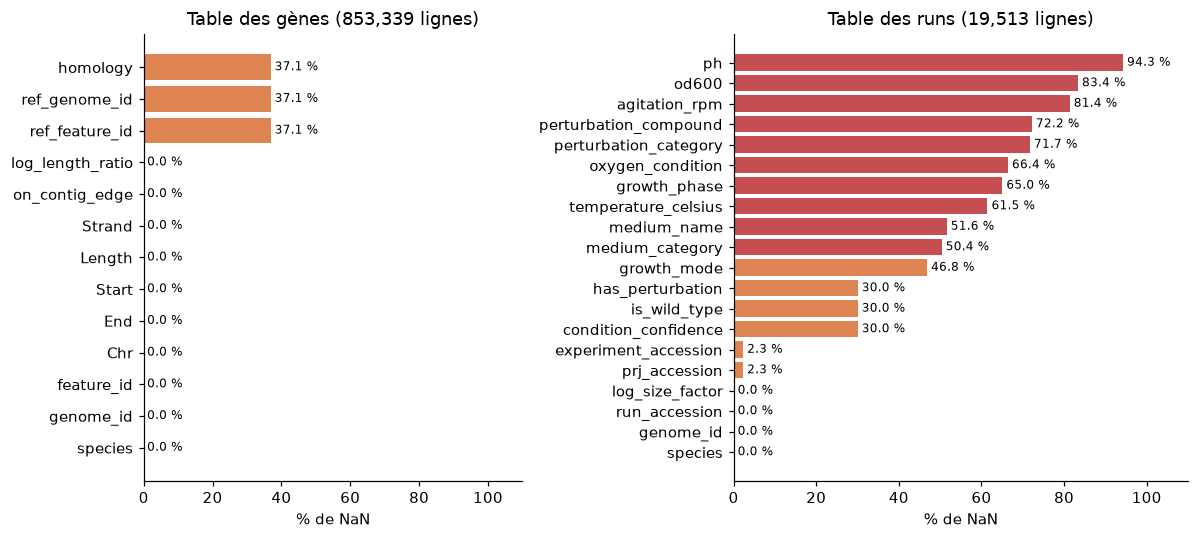

In [12]:
def nan_rate(df):
    return (df.isna().mean() * 100).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1, 1.2]})
for a, (name, df) in zip(ax, [("gènes", genes), ("runs", runs)]):
    r = nan_rate(df)
    a.barh(r.index, r.values, color=np.where(r.values > 50, "#C44E52", np.where(r.values > 0, "#DD8452", "#55A868")))
    for y, v in enumerate(r.values):
        a.text(v + 1, y, f"{v:.1f} %", va="center", fontsize=8)
    a.set(xlim=(0, 110), xlabel="% de NaN", title=f"Table des {name} ({len(df):,} lignes)")
plt.tight_layout()

### 4.1 Les NaN de `ref_*` et `homology` ne sont pas des données perdues

Ils sont **structurels**. Un gène n'a pas d'orthologue de référence quand :

- il est **dans le génome de référence lui-même** (il est sa propre référence),
- son espèce n'a **qu'un seul génome** (pas de référence à choisir),
- il **n'existe pas dans la souche de référence** (gène propre à la souche, acquis par exemple sur un plasmide).

In [13]:
ref_of_species = linked.groupby("species")["ref_genome_id"].agg(lambda s: s.mode()[0])
n_genomes = genes.groupby("species")["genome_id"].nunique()
missing = genes[genes["ref_feature_id"].isna()]
reason = np.select(
    [n_genomes.reindex(missing["species"]).to_numpy() == 1,
     missing["genome_id"].to_numpy() == missing["species"].map(ref_of_species).to_numpy()],
    ["espèce à un seul génome", "gène du génome de référence"],
    "gène sans orthologue dans la référence")
pd.Series(reason).value_counts().to_frame("gènes").assign(**{"% des NaN": lambda d: (100 * d["gènes"] / len(missing)).round(1)})

,gènes,% des NaN
espèce à un seul génome,184855,58.5
gène du génome de référence,131333,41.5
gène sans orthologue dans la référence,10,0.0


### 4.2 Les runs : beaucoup de conditions inconnues

Trois colonnes (`condition_confidence`, `is_wild_type`, `has_perturbation`) sont vides ensemble : ce sont les runs qui
n'ont **aucune fiche de curation**. Pour les autres, chaque champ est rempli seulement s'il était écrit dans la
description de l'expérience.

les trois vides ensemble : 30.0% | au moins une vide : 30.0%


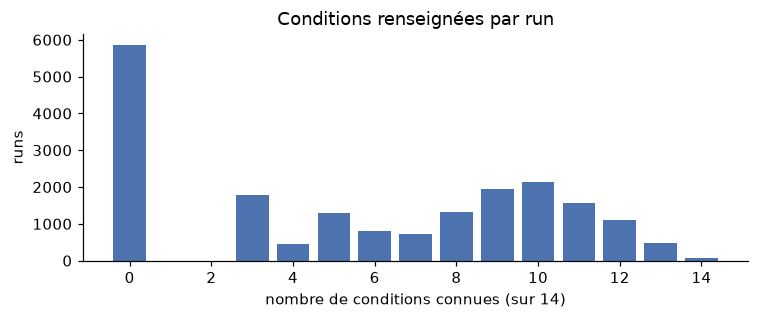

In [14]:
COND = ["condition_confidence", "is_wild_type", "medium_category", "medium_name", "temperature_celsius", "ph",
        "oxygen_condition", "agitation_rpm", "growth_mode", "growth_phase", "od600",
        "has_perturbation", "perturbation_category", "perturbation_compound"]
no_sheet = runs[["condition_confidence", "is_wild_type", "has_perturbation"]].isna()
print(f"les trois vides ensemble : {no_sheet.all(axis=1).mean():.1%} | au moins une vide : {no_sheet.any(axis=1).mean():.1%}")

n_known = runs[COND].notna().sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(*np.unique(n_known, return_counts=True), color="#4C72B0")
ax.set(xlabel=f"nombre de conditions connues (sur {len(COND)})", ylabel="runs", title="Conditions renseignées par run")
plt.tight_layout()

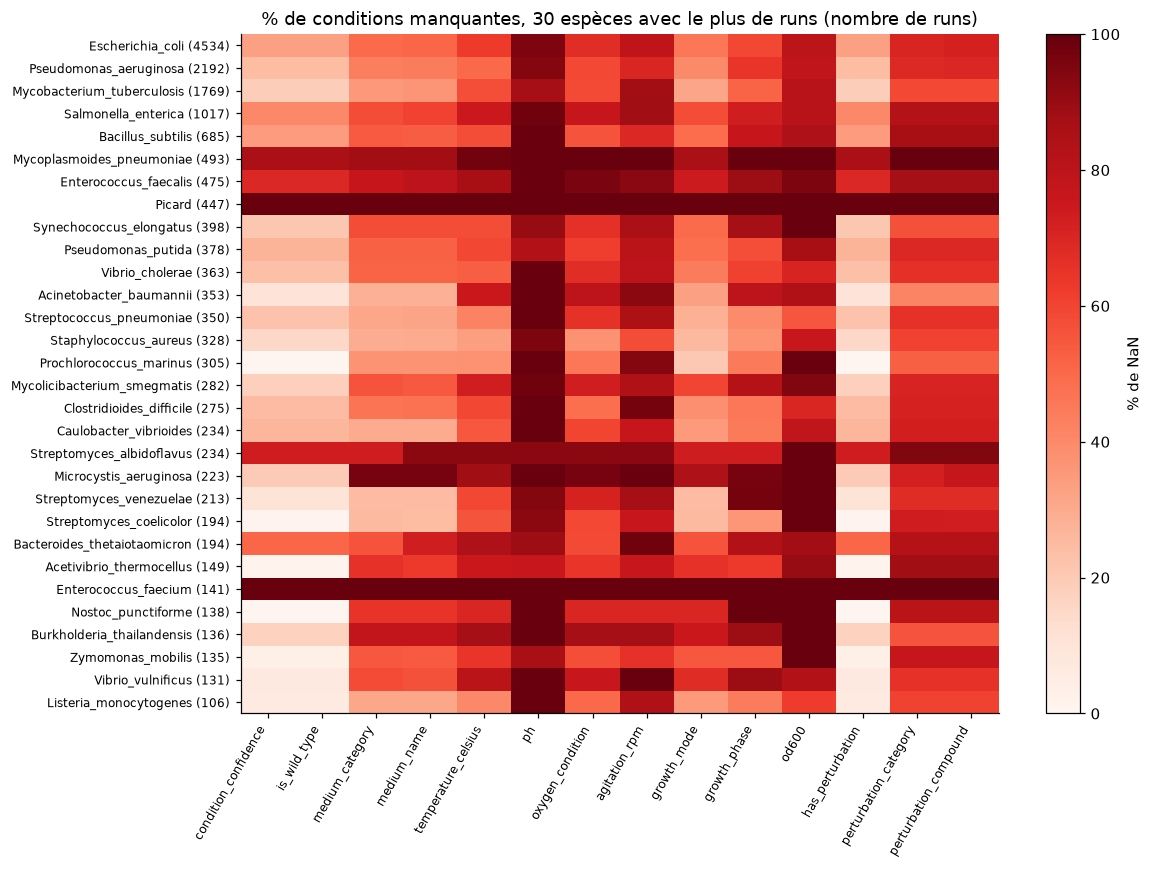

In [15]:
# NaN rate per species (rows) and per condition (columns), species with the most runs first
top = runs["species"].value_counts().index[:30]
heat = runs[runs["species"].isin(top)].groupby("species")[COND].agg(lambda s: s.isna().mean() * 100).loc[top]

fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(heat.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(COND)), COND, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(top)), [f"{s} ({n})" for s, n in runs["species"].value_counts().iloc[:30].items()], fontsize=8)
fig.colorbar(im, ax=ax, label="% de NaN")
ax.set_title("% de conditions manquantes, 30 espèces avec le plus de runs (nombre de runs)")
plt.tight_layout()

### 4.3 NaN vus depuis les observations, par région

Ce qui compte pour la métrique, c'est la part des **observations** dont le run n'a pas l'information. La région B (run
nouveau) est celle où les conditions servent le plus, puisque le run n'a jamais été vu.

In [16]:
run_missing = runs.set_index("run_accession")[COND].isna()
rows = {}
for name, df in splits.items():
    weight = df["run_accession"].value_counts()
    weight = weight[weight > 0]
    rows[name] = (run_missing.loc[weight.index].mul(weight, axis=0).sum() / weight.sum() * 100)
by_region = pd.DataFrame(rows).round(1)
by_region.style.background_gradient(cmap="Reds", vmin=0, vmax=100).format("{:.1f} %")

,train,A,B,C,D
condition_confidence,29.5 %,25.5 %,0.0 %,29.1 %,0.0 %
is_wild_type,29.5 %,25.5 %,0.0 %,29.1 %,0.0 %
medium_category,49.4 %,47.7 %,44.1 %,49.6 %,51.2 %
medium_name,50.8 %,48.9 %,44.1 %,51.0 %,51.2 %
temperature_celsius,61.3 %,59.7 %,50.5 %,61.5 %,56.5 %
ph,93.9 %,91.6 %,92.3 %,93.9 %,92.8 %
oxygen_condition,65.8 %,61.1 %,68.0 %,65.8 %,72.2 %
agitation_rpm,79.9 %,78.5 %,83.2 %,80.1 %,85.4 %
growth_mode,46.4 %,44.9 %,36.6 %,46.6 %,39.9 %
growth_phase,65.5 %,65.0 %,53.3 %,65.8 %,59.3 %


## 5. La cible `readcount`

zéros          : 1.8 %


non entiers    : 0.0 %


quantiles      : {'50%': '364', '90%': '4,396', '99%': '35,548', 'max': '17,295,952'}


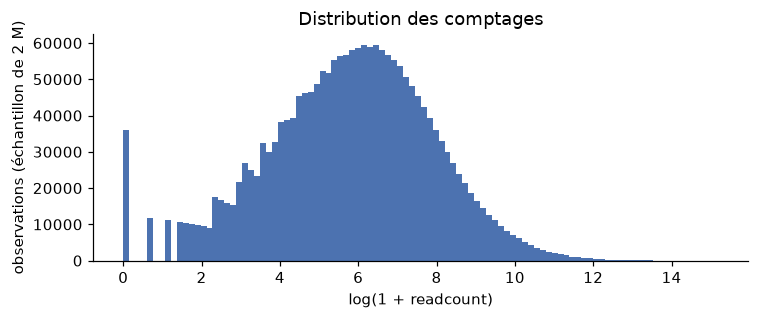

In [17]:
y = splits["train"]["readcount"].to_numpy()
print(f"zéros          : {np.mean(y == 0) * 100:.1f} %")
print(f"non entiers    : {np.mean(y != np.round(y)) * 100:.1f} %")
print("quantiles      :", {q: f"{v:,.0f}" for q, v in zip(["50%", "90%", "99%", "max"], np.percentile(y, [50, 90, 99, 100]))})

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log1p(y[np.random.default_rng(0).integers(0, len(y), 2_000_000)]), bins=100, color="#4C72B0")
ax.set(xlabel="log(1 + readcount)", ylabel="observations (échantillon de 2 M)", title="Distribution des comptages")
plt.tight_layout()

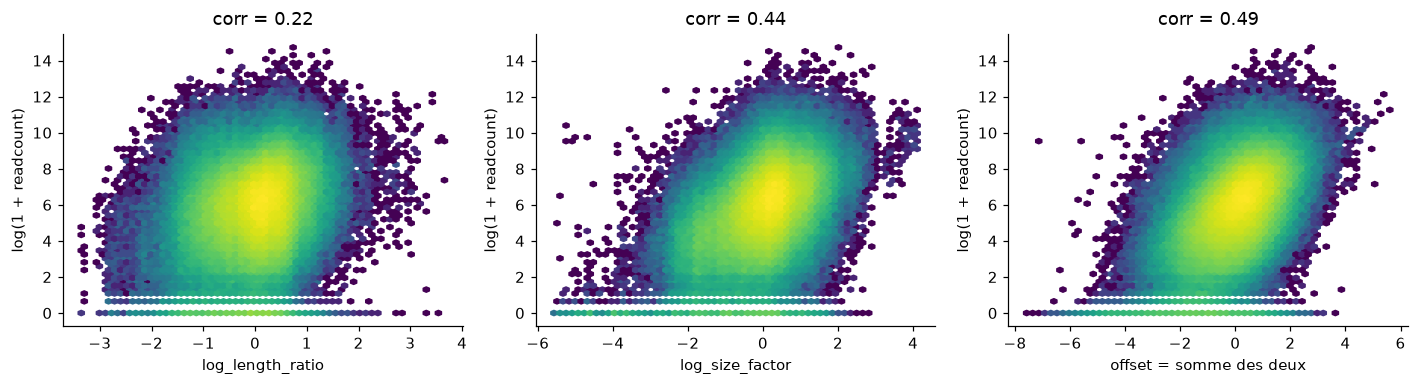

In [18]:
# Count against the two offsets, on a random sample of the training rows
rng = np.random.default_rng(0)
sample = splits["train"].iloc[rng.integers(0, len(splits["train"]), 300_000)]
sample = (sample.merge(genes[["genome_id", "feature_id", "log_length_ratio"]], on=["genome_id", "feature_id"], how="left")
                .merge(runs[["run_accession", "log_size_factor"]], on="run_accession", how="left"))
offset = sample["log_length_ratio"] + sample["log_size_factor"]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, x, label in [(ax[0], sample["log_length_ratio"], "log_length_ratio"),
                    (ax[1], sample["log_size_factor"], "log_size_factor"),
                    (ax[2], offset, "offset = somme des deux")]:
    a.hexbin(x, np.log1p(sample["readcount"]), gridsize=60, bins="log", cmap="viridis", mincnt=1)
    a.set(xlabel=label, ylabel="log(1 + readcount)")
    a.set_title(f"corr = {np.corrcoef(x, np.log1p(sample['readcount']))[0, 1]:.2f}")
plt.tight_layout()

### 5.1 Pourquoi une binomiale négative : la surdispersion

Pour une loi de Poisson, la variance égale la moyenne. Pour un même gène mesuré dans plusieurs runs, la variance des
comptages (après correction de la profondeur) est bien plus grande : c'est la **surdispersion**, que la binomiale
négative modélise avec son second paramètre.

Attention, cette variance mélange toutes les conditions du gène. Le `sigma` lu ici est donc celui d'un modèle qui ne
saurait rien du run. Un modèle qui explique l'effet de la condition laisse moins de variance, donc un `sigma` plus grand.

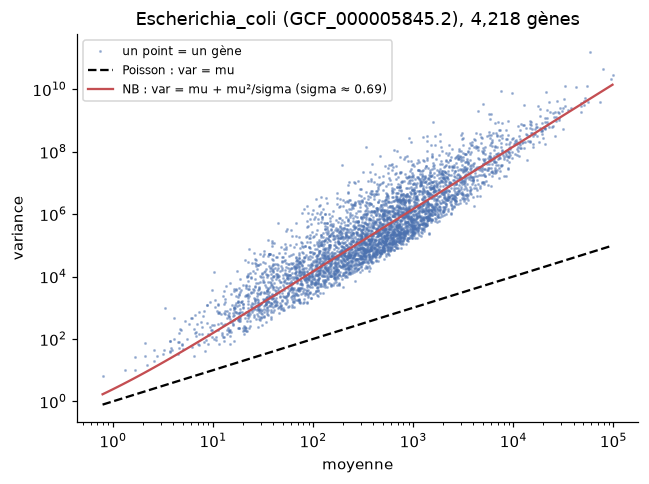

In [19]:
# One well-covered genome: per gene, mean and variance of the depth-normalised counts across its runs
gid = splits["train"]["genome_id"].value_counts().index[0]
sub = splits["train"][splits["train"]["genome_id"] == gid]
sub = sub.merge(runs[["run_accession", "log_size_factor"]], on="run_accession", how="left")
sub["norm"] = sub["readcount"] / np.exp(sub["log_size_factor"])
stats = sub.groupby("feature_id", observed=True)["norm"].agg(["mean", "var", "size"])
stats = stats[(stats["size"] >= 20) & (stats["mean"] > 0)]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(stats["mean"], stats["var"], ".", ms=2, alpha=0.4, color="#4C72B0", label="un point = un gène")
m = np.logspace(np.log10(stats["mean"].min()), np.log10(stats["mean"].max()), 100)
ax.loglog(m, m, "k--", label="Poisson : var = mu")
alpha = np.median((stats["var"] - stats["mean"]) / stats["mean"] ** 2)
ax.loglog(m, m + alpha * m ** 2, color="#C44E52", label=f"NB : var = mu + mu²/sigma (sigma ≈ {1 / alpha:.2f})")
ax.set(xlabel="moyenne", ylabel="variance", title=f"{sp_of_genome[gid]} ({gid}), {len(stats):,} gènes")
ax.legend(fontsize=8)
plt.tight_layout()

## 6. Ce que le modèle doit sortir : `(mu, sigma)`

Pour chaque ligne, le modèle rend :

- **`mu`** : le comptage attendu (la moyenne de la loi), `mu >= 0`,
- **`sigma`** : le paramètre de forme `r` de la binomiale négative, `sigma > 0`. **Ce n'est pas un écart-type.**
  La variance vaut `mu + mu² / sigma`, donc l'écart-type vaut `sqrt(mu + mu² / sigma)`.
  Grand `sigma` = loi serrée (proche de Poisson). Petit `sigma` = loi très étalée.
  Dans DESeq2 et beaucoup d'articles, on appelle **`alpha = 1 / sigma`** la dispersion.

Le score est la moyenne de `-log P(readcount | mu, sigma)` (plafonnée à 100 par ligne). Un `sigma` trop grand punit
fort les erreurs sur `mu`. Un `sigma` trop petit dilue la probabilité partout. Le bon `sigma` dépend donc de la
confiance qu'on a dans `mu` : il doit être plus petit pour un gène ou un run jamais vu.

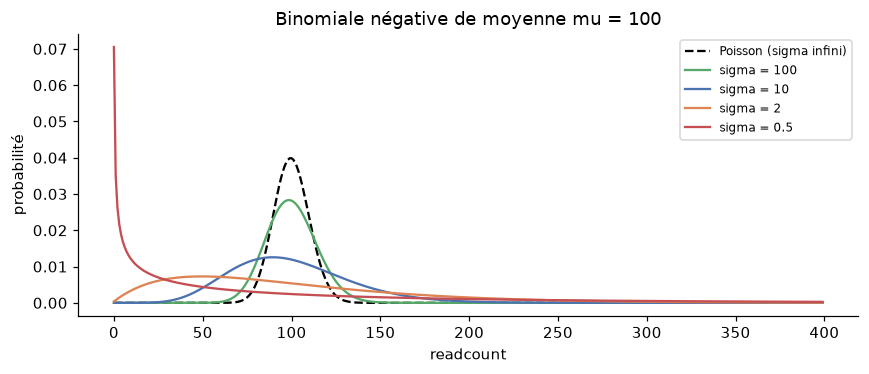

In [20]:
mu = 100
k = np.arange(0, 400)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(k, poisson.pmf(k, mu), "k--", label="Poisson (sigma infini)")
for r, col in zip([100, 10, 2, 0.5], ["#55A868", "#4C72B0", "#DD8452", "#C44E52"]):
    # scipy parametrisation: n = r, p = r / (r + mu)
    ax.plot(k, nbinom.pmf(k, r, r / (r + mu)), color=col, label=f"sigma = {r}")
ax.set(xlabel="readcount", ylabel="probabilité", title=f"Binomiale négative de moyenne mu = {mu}")
ax.legend(fontsize=8)
plt.tight_layout()

In [21]:
# Cost of a single observation (true count = 100) for a few predictions
cases = [(100, 50), (100, 5), (50, 50), (50, 5), (10, 50), (10, 5), (1e-3, 5)]
pd.DataFrame([{"mu prédit": m, "sigma prédit": s, "NLL (nats)": round(nb_nll([100], [m], [s]), 2)} for m, s in cases])

,mu prédit,sigma prédit,NLL (nats)
0,100.000,50,3.77
1,100.000,5,4.76
2,50.000,50,12.27
3,50.000,5,6.18
4,10.000,50,96.59
5,10.000,5,30.70
6,0.001,5,100.00


## 7. Les régions A, B, C, D

- **A** : gène vu et run vu, jamais ensemble.
- **B** : run nouveau, gène vu.
- **C** : gène nouveau, run vu.
- **D** : gène nouveau et run nouveau (affiché, pas classé).

Le classement est la moyenne de A, B et C.

In [22]:
counts = pd.DataFrame({name: df["species"].value_counts() for name, df in splits.items()}).fillna(0).astype(int)
counts = counts.sort_values("train", ascending=False)
print("génomes absents de train mais présents en évaluation :",
      sorted(set().union(*[set(splits[r]["genome_id"].unique()) for r in "ABCD"]) - set(splits["train"]["genome_id"].unique())))
counts.head(15)

génomes absents de train mais présents en évaluation : []


,train,A,B,C,D
species,,,,,
Escherichia_coli,16582550,719769,75924,74097,306
Pseudomonas_aeruginosa,10798080,468087,32802,43620,120
Mycobacterium_tuberculosis,6036130,258690,65348,25863,255
Salmonella_enterica,4136037,169509,34704,16595,128
Bacillus_subtilis,2535683,137062,20925,12222,90
Pseudomonas_putida,1813473,78008,21556,7818,84
Mycolicibacterium_smegmatis,1506116,70239,11890,6720,48
Streptomyces_venezuelae,1363536,65511,14406,6090,58
Picard,1359290,142419,0,7026,0


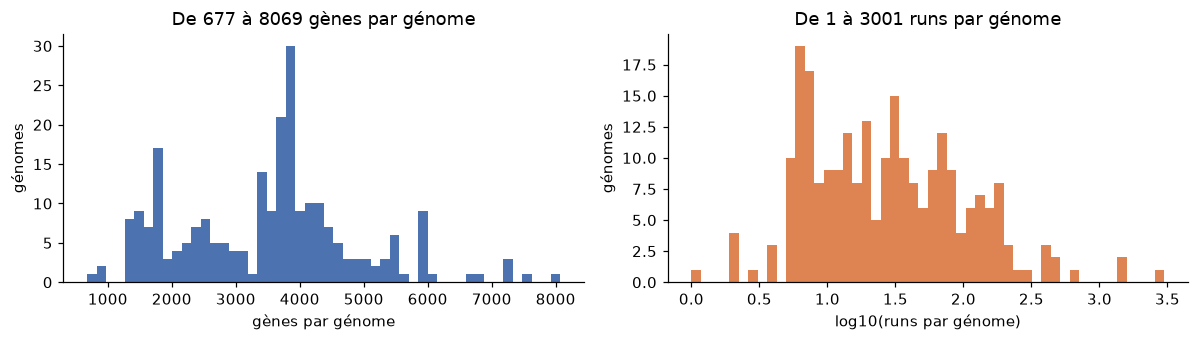

In [23]:
gpg = genes.groupby("genome_id").size()
rpg = runs.groupby("genome_id").size()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(gpg, bins=50, color="#4C72B0")
ax[0].set(xlabel="gènes par génome", ylabel="génomes", title=f"De {gpg.min()} à {gpg.max()} gènes par génome")
ax[1].hist(np.log10(rpg), bins=50, color="#DD8452")
ax[1].set(xlabel="log10(runs par génome)", ylabel="génomes", title=f"De {rpg.min()} à {rpg.max()} runs par génome")
plt.tight_layout()

## 8. Le génome (`.gbff`)

Un fichier par génome. Il contient la **séquence ADN assemblée de la souche** (le génome de référence de cette souche
publié par le NCBI, pas les lectures RNA-seq) et ses **annotations**. Les lectures de chaque run ont été alignées sur
cette séquence pour obtenir les comptages. La séquence est la même dans tous les runs du génome : seule la condition change.

Un génome complet (`NC_`, `NZ_CP`) est très fiable. Un génome en brouillon (`contig_`) est découpé en morceaux, et un
gène peut être coupé au bord d'un contig (`on_contig_edge`).

En plus de la séquence, chaque gène (`CDS`) a son nom, sa fonction (`/product`) et sa **séquence protéique**
(`/translation`). L'en-tête donne la **taxonomie** complète (embranchement, classe, ordre, famille, genre), utile
pour rapprocher les espèces par famille.

In [24]:
from Bio import SeqIO

path = GENOMES / "GCF_000005845.2.gbff"
record = next(SeqIO.parse(str(path), "genbank"))
print(record.id, "|", record.description, "|", len(record.seq), "pb")
print("taxonomie :", " > ".join(record.annotations["taxonomy"]))
print("séquence  :", str(record.seq[:60]), "...")

cds = [f for f in record.features if f.type == "CDS"]
print(f"\n{len(cds)} CDS, premier :")
first = cds[0]
for key in ["gene", "product", "protein_id", "translation"]:
    print(f"  {key:<12}: {first.qualifiers.get(key, ['?'])[0]}")

NC_000913.3 | Escherichia coli str. K-12 substr. MG1655, complete genome | 4641652 pb
taxonomie : Bacteria > Pseudomonadati > Pseudomonadota > Gammaproteobacteria > Enterobacterales > Enterobacteriaceae > Escherichia
séquence  : AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTC ...

4318 CDS, premier :
  gene        : thrL
  product     : thr operon leader peptide
  protein_id  : NP_414542.1
  translation : MKRISTTITTTITITTGNGAG


In [25]:
# Promoter of the first gene: the 200 bp just upstream, as in the baseline
row = genes[(genes["genome_id"] == "GCF_000005845.2") & (genes["feature_id"] == "cds-NP_414543.1")].iloc[0]
start, end = int(row["Start"]), int(row["End"])
upstream = record.seq[max(start - 1 - 200, 0):start - 1] if row["Strand"] == "+" else record.seq[end:end + 200].reverse_complement()
print(row[["feature_id", "Chr", "Start", "End", "Strand", "Length"]].to_dict())
print("promoteur (200 pb en amont) :", str(upstream))
print("gène (60 premières pb)      :", str(record.seq[start - 1:start - 1 + 60]))

{'feature_id': 'cds-NP_414543.1', 'Chr': 'NC_000913.3', 'Start': '337', 'End': '2799', 'Strand': '+', 'Length': 2463.0}
promoteur (200 pb en amont) : CCAATATAGGCATAGCGCACAGACAGATAAAAATTACAGAGTACACAACATCCATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCACAGGTAACGGTGCGGGCTGACGCGTACAGGAAACACAGAAAAAAGCCCGCACCTGACAGTGCGGGCTTTTTTTTTCGACCAAAGGTAACGAGGTAACAACC
gène (60 premières pb)      : ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAACGTTTTCTGCGTGTT


In [26]:
# Taxonomy of every genome, read from the header only (fast, no full parse)
def read_lineage(path):
    lines, inside = [], False
    with open(path, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            if line.startswith("  ORGANISM"):
                inside = True
                continue
            if inside:
                if not line.startswith("            "):
                    break
                lines.append(line.strip())
            if line.startswith("FEATURES") or line.startswith("ORIGIN"):
                break
    return [t for t in " ".join(lines).rstrip(".").split("; ") if t]

def ranks(lineage):
    # Bacterial rank names end with fixed suffixes: phylum -ota, order -ales, family -aceae
    pick = lambda suffix: next((t for t in lineage if t.endswith(suffix)), None)
    family = pick("aceae")
    genus = lineage[lineage.index(family) + 1] if family and lineage.index(family) + 1 < len(lineage) else None
    return {"domaine": lineage[0] if lineage else None, "embranchement": pick("ota"),
            "ordre": pick("ales"), "famille": family, "genre": genus, "lignée": "; ".join(lineage)}

taxo = pd.DataFrame({p.stem: ranks(read_lineage(p)) for p in sorted(GENOMES.glob("*.gbff"))}).T
taxo["species"] = sp_of_genome.reindex(taxo.index)
taxo = taxo.dropna(subset=["species"])
print(f"{len(taxo)} génomes du jeu lus, {taxo['lignée'].eq('').sum()} sans taxonomie dans l'en-tête")
print(f"{taxo['embranchement'].nunique()} embranchements, {taxo['famille'].nunique()} familles, {taxo['species'].nunique()} espèces")
taxo.drop_duplicates("species").sort_values(["embranchement", "ordre", "famille"])[
    ["species", "embranchement", "ordre", "famille", "genre"]].head(25)

243 génomes du jeu lus, 0 sans taxonomie dans l'en-tête


14 embranchements, 53 familles, 87 espèces


,species,embranchement,ordre,famille,genre
GCF_000020425.1,Bifidobacterium_longum,Actinomycetota,Bifidobacteriales,Bifidobacteriaceae,Bifidobacterium
GCF_008639165.1,Streptomyces_venezuelae,Actinomycetota,Kitasatosporales,Streptomycetaceae,Streptomyces
GCF_008931305.1,Streptomyces_coelicolor,Actinomycetota,Kitasatosporales,Streptomycetaceae,Streptomyces
GCF_045039635.1,Streptomyces_albidoflavus,Actinomycetota,Kitasatosporales,Streptomycetaceae,Streptomyces
GCF_000011325.1,Corynebacterium_glutamicum,Actinomycetota,Mycobacteriales,Corynebacteriaceae,Corynebacterium
GCF_000007865.1,Mycobacterium_avium,Actinomycetota,Mycobacteriales,Mycobacteriaceae,Mycobacterium
GCF_000008585.1,Mycobacterium_tuberculosis,Actinomycetota,Mycobacteriales,Mycobacteriaceae,Mycobacterium
GCF_000069185.1,Mycobacteroides_abscessus,Actinomycetota,Mycobacteriales,Mycobacteriaceae,Mycobacteroides
GCF_000331165.2,Mycolicibacterium_smegmatis,Actinomycetota,Mycobacteriales,Mycobacteriaceae,Mycolicibacterium
GCF_020542785.2,Rhodococcus_opacus,Actinomycetota,Mycobacteriales,Nocardiaceae,Rhodococcus


## À retenir (relevé du 2026-11-04 sur le mode `train`)

**Le jeu**

- 69,2 M observations d'entraînement, 853 339 gènes, 19 513 runs, 243 génomes, 87 « espèces » (dont `Picard`, qui est en fait *E. coli*).
- Régions d'évaluation : A 3,26 M, B 0,80 M, C 0,31 M, D 3 741 observations.
- **Aucun génome nouveau en évaluation** : chaque génome a déjà des observations en train. Un embedding d'espèce ou de génome s'apprend donc toujours.
- De 677 à 8 069 gènes par génome, et de 1 à 3 001 runs par génome. *E. coli* (36 souches) et *P. aeruginosa* pèsent 40 % du train.

**Les NaN**

- Table des gènes : seuls `ref_genome_id`, `ref_feature_id` et `homology` ont des NaN (37,1 %), et ils sont **structurels**. 58,5 % viennent d'espèces à un seul génome, 41,5 % de gènes du génome de référence. Les gènes sans orthologue sont 10 en tout.
- Table des runs : 30 % des runs n'ont **aucune fiche de curation**. Au total, chaque condition manque dans 47 % (`growth_mode`) à 94 % (`ph`) des runs.
- `Picard` et `Enterococcus_faecium` n'ont aucune condition renseignée.
- **Tous les runs des régions B et D ont une fiche** (0 % de NaN sur `condition_confidence`), contre 29,5 % sans fiche en train.

**La cible**

- Médiane 364 lectures, 99e centile 35 548, maximum 17,3 M. Seulement 1,8 % de zéros, et tous les comptages sont entiers.
- Forte surdispersion : la variance croît comme `mu²`, la binomiale négative est le bon choix.
- Les offsets seuls expliquent peu (corrélation 0,49 avec `log1p(readcount)`). L'essentiel vient de l'identité du gène et de la condition.